# HeatSeeker: Detecting Thermal Events in Low-Resolution Infrared Frames with Classical ML
**ES 335 · Dhruv Anil Gupta (24110108) · Bhoomi Anurag Agrawal (24110073)**

## 0. Question, claim and scope
**Research question.** Can simple spatial heat features from a 24 × 32 infrared frame classify a *thermal event* in real time, and how much do non-linear tree models (CART, Random Forest) improve on a Linear SVM baseline in accuracy and false alarms?

**Unit and target.** One row = one thermal frame (24 × 32 pixels = 768 temperatures in °C). Target: **+1 = thermal event** (a person crossing the doorway, which creates a localised warm blob), **−1 = normal** (confirmed empty room).

**What changed from the proposal (and why).**
- *Dataset:* we use the **TIDOS** low-resolution thermal dataset (6 recordings, sensor 1, 16 Hz) instead of the Xenedo dataset named in the proposal. Our final working set has **1,507 labelled frames**. TIDOS provides independent ground-truth occupancy labels, so our target is *not* generated from our own features. `[https://vip.bu.edu/projects/vsns/cossy/datasets/tidos/download/]`
- *Label meaning:* "anomaly" is operationalised as a *localised transient heat event*, not a fault diagnosis.

**Limits of the claim.** One sensor, one doorway, six recordings. Results show how well these features work *on this setup*; they are not a general fault detector.


## 1. Setup and reproducibility
All core models (Linear SVM, CART, Random Forest, Lasso) are implemented **from scratch in NumPy**. scikit-learn is used only for (i) splitting by group, (ii) StandardScaler, (iii) metrics, and (iv) *reference* models used to sanity-check our implementations.


In [ ]:
# System and File I/O
import os
import glob
import json
import time

# Numerical Computation & Visualisation
import numpy as np
import scipy.io
import pandas as pd
from IPython.display import display
import matplotlib.pyplot as plt

# Benchmark Comparisons & Preprocessing Only (Core SVM & Tree are pure NumPy)
from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["image.cmap"] = "jet"
np.random.seed(42)

In [48]:

TIDOS_ROOT = os.environ.get("TIDOS_ROOT", "./TIDOS")
SENSOR_ID = 1
FPS = 16                              # TIDOS sensor frame rate (frames per second)
FRAME_BUDGET_MS = 1000.0 / FPS        # 62.5 ms available per frame for "real time"


## 2. Data understanding and label construction
**Source and access.** TIDOS stores each recording as one JSON file per second (16 frames of 24 × 32 °C values) plus a `.mat` file with the true number of people in the room at every frame.

**How rows and labels are built (`load_tidos_frames`).**
- **+1 (thermal event):** frames from 3 before to 1 after every change in the ground-truth occupancy count, i.e. someone is crossing the sensor's field of view (5 frames ≈ 0.3 s per event).
- **−1 (normal):** frames where the room is truly empty (count = 0) and **at least 64 frames (4 s) away** from any crossing. We keep every 4th such frame to reduce near-duplicates. `Edge_Cases` contributes no negatives because people linger at the doorway there.
- Negatives are capped at 1.2 × the positive count → **685 event frames, 822 normal frames, 1,507 total**.

**Data-quality checks.** No NaN pixels; temperatures range from about 17.5 °C to 34 °C.

**Important design note.** Because we sub-sample empty frames, the 45 / 55 class mix is *our choice*, not the real-world rate (real deployments are mostly empty room). That is why we report precision, recall and the **false-positive rate (FPR)**, not accuracy alone.


In [49]:
RECORDINGS = [
    "Edge_Cases", "High_Activity", "Lecture",
    "Lunch_Meeting_1", "Lunch_Meeting_2", "Lunch_Meeting_3"
]

def load_tidos_frames(tidos_root, recordings, sensor_id=1, pre=3, post=1, empty_buffer=64):
    """
    Load 24x32 thermal frames (deg C) and clean ground-truth labels:
      +1: frames right at a ground-truth occupancy crossing [idx - pre, idx + post]
      -1: confirmed empty-room frames (occ == 0) at least `empty_buffer` frames away
          from any crossing (excluding Edge_Cases where people linger/turn around at occ==0).
    """
    pos_frames, pos_groups, pos_recs = [], [], []
    neg_frames, neg_groups, neg_recs = [], [], []
    rng = np.random.default_rng(42)

    for rec in recordings:
        data_dir = os.path.join(tidos_root, "Data", rec, f"{rec.lower()}_sensor_{sensor_id}")
        gt_path = os.path.join(tidos_root, "Labels", rec, f"{rec.lower()}_sensor_{sensor_id}_labels.mat")

        occ = scipy.io.loadmat(gt_path)["label"].ravel().astype(np.int32)
        json_paths = sorted(glob.glob(os.path.join(data_dir, "*.json")))
        n_frames = min(len(occ), len(json_paths) * 16)
        occ = occ[:n_frames]

        change_idx = np.where(np.diff(occ) != 0)[0] + 1

        # 1. Positive (+1) crossing frames: tight window around transition
        pos_mask = np.zeros(n_frames, dtype=bool)
        for idx in change_idx:
            pos_mask[max(0, idx - pre):min(n_frames, idx + post + 1)] = True
        pos_indices = np.where(pos_mask)[0]

        # 2. Negative (-1) empty-floor frames: skip Edge_Cases (doorway turn-arounds)
        if rec != "Edge_Cases":
            near_change = np.zeros(n_frames, dtype=bool)
            for idx in change_idx:
                near_change[max(0, idx - empty_buffer):min(n_frames, idx + empty_buffer + 1)] = True
            neg_candidates = np.where((occ == 0) & (~near_change))[0][::4]
        else:
            neg_candidates = np.array([], dtype=np.int64)

        selected_idx = np.concatenate([pos_indices, neg_candidates])
        if len(selected_idx) == 0:
            continue

        # Load only needed JSON files
        needed_file_ids = np.unique(selected_idx // 16)
        chunk_cache = {}
        for fid in needed_file_ids:
            with open(json_paths[fid], "r") as f:
                arr = np.asarray(json.load(f)["Frames_B"], dtype=np.float32)
            chunk_cache[int(fid)] = arr.reshape(-1, 24, 32)

        for t in pos_indices:
            fid, offset = int(t // 16), int(t % 16)
            pos_frames.append(chunk_cache[fid][offset])
            pos_groups.append(f"{rec}_chunk_{fid // 5}")
            pos_recs.append(rec)

        for t in neg_candidates:
            fid, offset = int(t // 16), int(t % 16)
            neg_frames.append(chunk_cache[fid][offset])
            neg_groups.append(f"{rec}_chunk_{fid // 5}")
            neg_recs.append(rec)

    # Balance negative class to ~1.2x positive class
    n_keep_neg = min(len(neg_frames), int(len(pos_frames) * 1.2))
    keep_neg_idx = np.sort(rng.choice(len(neg_frames), size=n_keep_neg, replace=False))

    all_frames = np.asarray(pos_frames + [neg_frames[i] for i in keep_neg_idx], dtype=np.float32)
    all_labels = np.concatenate([
        np.ones(len(pos_frames), dtype=np.int32),
        -np.ones(n_keep_neg, dtype=np.int32)
    ])
    all_groups = np.asarray(pos_groups + [neg_groups[i] for i in keep_neg_idx])
    all_recs   = np.asarray(pos_recs + [neg_recs[i] for i in keep_neg_idx])

    return all_frames, all_labels, all_groups, all_recs

frames, y_all, group_ids, rec_names = load_tidos_frames(TIDOS_ROOT, RECORDINGS, sensor_id=SENSOR_ID)

print("Loaded frames matrix shape (N, H, W):", frames.shape)
print("Hotspot (+1) frames:", int((y_all == 1).sum()))
print("Empty   (-1) frames:", int((y_all == -1).sum()))
print(f"Temp range: {frames.min():.2f}°C to {frames.max():.2f}°C")

Loaded frames matrix shape (N, H, W): (1507, 24, 32)
Hotspot (+1) frames: 685
Empty   (-1) frames: 822
Temp range: 17.45°C to 34.02°C


**Visual check.** Top row: three normal frames; bottom row: three event frames (same colour scale 17–32 °C). Events show a compact warm blob a few °C above the room; normal frames are close to uniform. This is the intuition our features try to capture.


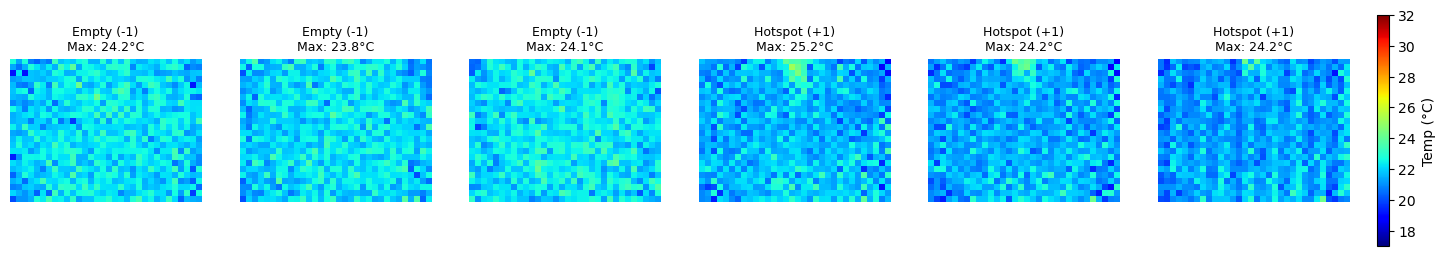

In [50]:
neg_idx = np.where(y_all == -1)[0][:3]
pos_idx = np.where(y_all == 1)[0][:3]
show_idx = np.concatenate([neg_idx, pos_idx])

fig, axes = plt.subplots(1, len(show_idx), figsize=(3 * len(show_idx), 3))
for ax, idx in zip(axes, show_idx):
    im = ax.imshow(frames[idx], cmap="jet", vmin=17, vmax=32, interpolation="nearest")
    tag = "Hotspot (+1)" if y_all[idx] == 1 else "Empty (-1)"
    ax.set_title(f"{tag}\nMax: {frames[idx].max():.1f}°C", fontsize=9)
    ax.axis("off")

plt.colorbar(im, ax=axes, fraction=0.02, pad=0.02, label="Temp (°C)")
plt.show()

## 3. Train / validation / test split
We split **70 / 15 / 15** using `GroupShuffleSplit`, where each group is a **5-second block** of one recording (80 frames). Neighbouring frames of the same crossing are nearly identical, so a random frame-level split would leak information and inflate the test score. Splitting by block keeps them together.

| Split | Frames | Role |
|---|---|---|
| Train (1,055) | fit models, scaler and background | learning only |
| Validation (230) | hyper-parameter tuning and model comparison | all tuning decisions |
| Test (222) | **final one-time evaluation** | never used for tuning |

**Empty-room background.** For each recording we take the pixel-wise **median of the *training* empty frames** as a reference of the room. Validation and test frames are only ever compared against this training-derived reference, so no validation/test information is used to build it. (`Edge_Cases` has no empty frames, so it uses the global training median.)

**Caveat shown by the audit table below.** Class balance differs strongly by recording (e.g. `Lecture` is mostly empty, `High_Activity` mostly events), and group splitting does not stratify. We check this honestly with a leave-one-recording-out test in Section 12.


In [51]:
# 1. Group-aware split: 70% Train, 15% Val, 15% Test (no adjacent frames shared across splits)
gss1 = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=42)
train_idx, temp_idx = next(gss1.split(frames, y_all, groups=group_ids))

gss2 = GroupShuffleSplit(n_splits=1, test_size=0.50, random_state=42)
val_rel, test_rel = next(gss2.split(frames[temp_idx], y_all[temp_idx], groups=group_ids[temp_idx]))
val_idx = temp_idx[val_rel]
test_idx = temp_idx[test_rel]

y_train, y_val, y_test = y_all[train_idx], y_all[val_idx], y_all[test_idx]

# 2. Compute stationary empty-floor background STRICTLY from training empty (-1) frames
train_empty_frames = frames[train_idx][y_train == -1]
bg_global = np.median(train_empty_frames, axis=0)

bg_by_rec = {}
for rec in np.unique(rec_names):
    mask = (rec_names[train_idx] == rec) & (y_train == -1)
    if np.any(mask):
        bg_by_rec[rec] = np.median(frames[train_idx][mask], axis=0)
    else:
        bg_by_rec[rec] = bg_global

print(f"Train: {len(train_idx)} (+1: {(y_train==1).sum()}, -1: {(y_train==-1).sum()})")
print(f"Val:   {len(val_idx)} (+1: {(y_val==1).sum()}, -1: {(y_val==-1).sum()})")
print(f"Test:  {len(test_idx)} (+1: {(y_test==1).sum()}, -1: {(y_test==-1).sum()})")
print(f"Training background median temp: {np.median(bg_global):.2f}°C")

Train: 1055 (+1: 486, -1: 569)
Val:   230 (+1: 88, -1: 142)
Test:  222 (+1: 111, -1: 111)
Training background median temp: 21.47°C


In [52]:
# Data audit: class balance per recording and per split 
import pandas as pd

audit = pd.DataFrame({"recording": rec_names, "label": y_all})
tab = audit.pivot_table(index="recording", columns="label", aggfunc=len, fill_value=0)
tab.columns = ["empty (-1)", "crossing (+1)"]
print("Class counts per recording (whole dataset):")
display(tab)

split_tab = pd.DataFrame({
    "train": pd.Series(rec_names[train_idx]).value_counts(),
    "val":   pd.Series(rec_names[val_idx]).value_counts(),
    "test":  pd.Series(rec_names[test_idx]).value_counts(),
}).fillna(0).astype(int)
print("\nFrames per recording in each split:")
display(split_tab)

# Sanity checks on the raw frames
print(f"\nNaN pixels: {int(np.isnan(frames).sum())}   |   "
      f"temperature range: {frames.min():.1f} to {frames.max():.1f} deg C")
print(f"Natural-data caveat: empty frames were sub-sampled (every 4th) and capped at 1.2x the "
      f"crossing count, so this 45/55 class mix is a design choice, not the real-world rate.")


Class counts per recording (whole dataset):


,empty (-1),crossing (+1)
recording,,
Edge_Cases,0,70
High_Activity,45,255
Lecture,150,10
Lunch_Meeting_1,394,65
Lunch_Meeting_2,54,40
Lunch_Meeting_3,179,245



Frames per recording in each split:


,train,val,test
Edge_Cases,40,25,5
High_Activity,214,25,61
Lecture,106,25,29
Lunch_Meeting_1,335,69,55
Lunch_Meeting_2,67,21,6
Lunch_Meeting_3,293,65,66



NaN pixels: 0   |   temperature range: 17.5 to 34.0 deg C
Natural-data caveat: empty frames were sub-sampled (every 4th) and capped at 1.2x the crossing count, so this 45/55 class mix is a design choice, not the real-world rate.


## 4. Feature engineering and scaling
Each frame is turned into **40 numeric features**:

| Group | # | What it captures | Why |
|---|---|---|---|
| Heat above background (`delta = frame − background`) | 8 | max, mean, std, 95th/99th percentile, share of pixels > 1.5 / 2.5 / 4 °C | a person is warmer than the empty room |
| Room-invariant contrast | 4 | frame minus its own 25th percentile; frame std | works without a calibrated background |
| **Spatial gradient** ($\nabla T_x,\nabla T_y$, magnitude $G=\sqrt{G_x^2+G_y^2}$) | 4 | max, mean, 95th percentile of $G$, share of pixels with $G>1$ | a warm blob has sharp edges (the proposal's main idea) |
| 3 × 4 zone pooling | 24 | max and mean of `delta` in 12 blocks of 8 × 8 pixels | where in the frame the heat is |

**Scaling.** `StandardScaler` is **fit on training features only** and then applied unchanged to validation and test. Scaling is required by the SVM; trees do not need it but use the same matrix for a single consistent pipeline.


In [53]:
def extract_thermal_features(frame, bg_frame):
    """Extract 40 fast, physical hotspot features from one 24x32 thermal frame."""
    delta = frame - bg_frame                          # Temperature rise over empty floor
    frame_rel = frame - np.percentile(frame, 25)      # Room-invariant contrast over floor

    # Spatial thermal gradients (like [gx, gy] = gradient(delta) in MATLAB)
    gy, gx = np.gradient(delta)
    grad_mag = np.sqrt(gx**2 + gy**2)

    features = [
        # Peak & spread of background-subtracted rise (8)
        float(delta.max()),
        float(delta.mean()),
        float(delta.std()),
        float(np.percentile(delta, 95)),
        float(np.percentile(delta, 99)),
        float(np.sum(delta > 1.5) / 768.0),
        float(np.sum(delta > 2.5) / 768.0),
        float(np.sum(delta > 4.0) / 768.0),
        # Room-invariant contrast & frame spread (4)
        float(frame_rel.max()),
        float(np.percentile(frame_rel, 95)),
        float(np.sum(frame_rel > 3.0) / 768.0),
        float(frame.std()),
        # Spatial thermal gradient features (4)
        float(grad_mag.max()),
        float(grad_mag.mean()),
        float(np.percentile(grad_mag, 95)),
        float(np.sum(grad_mag > 1.0) / 768.0),
    ]

    # Coarse 3x4 spatial zone pooling (each zone is 8x8 pixels -> 12 max + 12 mean = 24)
    blocks = delta.reshape(3, 8, 4, 8)
    features.extend(blocks.max(axis=(1, 3)).ravel().tolist())
    features.extend(blocks.mean(axis=(1, 3)).ravel().tolist())

    return np.asarray(features, dtype=np.float64)

def build_feature_matrix(indices):
    return np.vstack([
        extract_thermal_features(frames[i], bg_by_rec[rec_names[i]])
        for i in indices
    ])

X_train = build_feature_matrix(train_idx)
X_val   = build_feature_matrix(val_idx)
X_test  = build_feature_matrix(test_idx)

# Fit StandardScaler strictly on X_train
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled   = scaler.transform(X_val)
X_test_scaled  = scaler.transform(X_test)

print("Feature matrices ready -> Train:", X_train_scaled.shape, "Val:", X_val_scaled.shape, "Test:", X_test_scaled.shape)

Feature matrices ready -> Train: (1055, 40) Val: (230, 40) Test: (222, 40)


## 5. Models
| Role | Model | Why it fits this problem |
|---|---|---|
| **Baseline** | Linear soft-margin SVM (subgradient descent) | tests whether one linear boundary on heat features is enough |
| Candidate 1 | CART decision tree (Gini) | learns threshold rules such as "peak heat > x and hot area > y"; interpretable |
| Candidate 2 | Random Forest (bagged trees) | averages many trees so one noisy feature or pixel matters less |
| Feature filter | Lasso (coordinate descent) | finds which features carry signal (Section 11) |



### 5.1 Baseline: Linear SVM from scratch
We minimise the regularised hinge-loss objective

$$J(w,b)=\tfrac{\lambda}{2}\lVert w\rVert^2+\frac1n\sum_i\max\bigl(0,\;1-y_i(w^\top x_i+b)\bigr),\qquad y_i\in\{-1,+1\}$$

with stochastic subgradient descent: if a sample violates the margin ($y_i(w^\top x_i+b)<1$) we step along $-(\lambda w - y_i x_i)$ and $y_i$ for $b$; otherwise we only shrink $w$. The plot shows the objective per epoch, which should decrease and flatten, confirming convergence. Predictions are $\text{sign}(w^\top x + b)$.


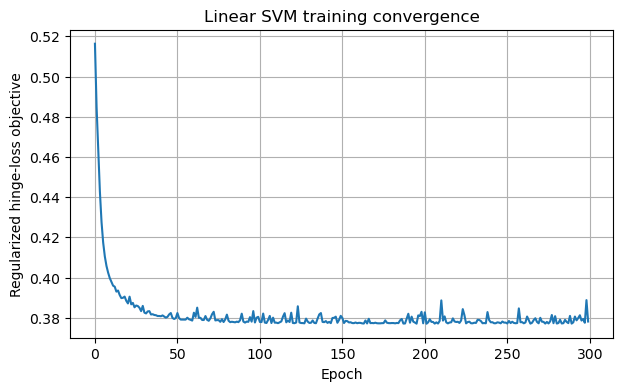

True labels (first 10): [1 1 1 1 1 1 1 1 1 1]
SVM predictions (first 10): [1 1 1 1 1 1 1 1 1 1]


In [54]:
def train_linear_svm(X, y, learning_rate=0.001, lambda_reg=0.01,
                     epochs=300, random_state=42):
    """Train a linear soft-margin SVM using stochastic subgradient descent."""
    X = np.asarray(X, dtype=np.float64)
    y = np.asarray(y, dtype=np.float64)

    if not np.all(np.isin(y, [-1, 1])):
        raise ValueError("SVM labels must be -1 or +1.")

    n_samples, n_features = X.shape
    w = np.zeros(n_features, dtype=np.float64)
    b = 0.0
    rng = np.random.default_rng(random_state)
    losses = []

    for epoch in range(epochs):
        indices = rng.permutation(n_samples)

        for i in indices:
            margin = y[i] * (np.dot(X[i], w) + b)

            if margin >= 1:
                grad_w = lambda_reg * w
                grad_b = 0.0
            else:
                grad_w = lambda_reg * w - y[i] * X[i]
                grad_b = -y[i]

            w -= learning_rate * grad_w
            b -= learning_rate * grad_b

        # Track objective after each epoch for convergence inspection.
        margins = y * (X @ w + b)
        hinge = np.maximum(0.0, 1.0 - margins)
        objective = 0.5 * lambda_reg * np.dot(w, w) + np.mean(hinge)
        losses.append(objective)

    return w, b, np.asarray(losses)


def predict_linear_svm(X, w, b):
    scores = np.asarray(X) @ w + b
    return np.where(scores >= 0, 1, -1), scores


w, b, svm_losses = train_linear_svm(
    X_train_scaled,
    y_train,
    learning_rate=0.001,
    lambda_reg=0.01,
    epochs=300,
    random_state=42
)

svm_val_preds, svm_val_scores = predict_linear_svm(
    X_val_scaled, w, b
)

plt.figure(figsize=(7, 4))
plt.plot(svm_losses)
plt.xlabel("Epoch")
plt.ylabel("Regularized hinge-loss objective")
plt.title("Linear SVM training convergence")
plt.grid(True)
plt.show()

print("True labels (first 10):", y_val[:10])
print("SVM predictions (first 10):", svm_val_preds[:10])

### 5.2 CART decision tree from scratch
At every node we choose the feature and threshold that maximise the drop in **Gini impurity**

$$G(S)=1-\sum_k p_k^2,\qquad \text{gain}=G(\text{parent})-\tfrac{n_L}{n}G(\text{left})-\tfrac{n_R}{n}G(\text{right}).$$

To keep runtime low, each feature tries up to 19 candidate thresholds (5th–95th percentiles). Overfitting is limited by `max_depth`, `min_samples_split`, `min_samples_leaf` and a minimum gain. Trees do not need scaling: monotonic rescaling does not change the order of split candidates.


In [55]:
def calculate_gini(y):
    if len(y) == 0:
        return 0.0
    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / counts.sum()
    return float(1.0 - np.sum(probabilities ** 2))


def find_best_split(X, y, min_samples_leaf=5, min_impurity_decrease=1e-5, feature_indices=None):
    n_samples, n_features = X.shape
    parent_gini = calculate_gini(y)

    best_gain = 0.0
    best_feature = None
    best_threshold = None

    if feature_indices is None:
        feature_indices = np.arange(n_features)

    for feature in feature_indices:
        values = np.unique(X[:, feature])

        # Use a limited set of candidate thresholds for runtime.
        if len(values) > 20:
            values = np.percentile(values, np.linspace(5, 95, 19))
            values = np.unique(values)

        for threshold in values:
            left_mask = X[:, feature] <= threshold
            n_left = int(np.sum(left_mask))
            n_right = n_samples - n_left

            if n_left < min_samples_leaf or n_right < min_samples_leaf:
                continue

            y_left = y[left_mask]
            y_right = y[~left_mask]

            weighted_child_gini = (
                (n_left / n_samples) * calculate_gini(y_left)
                + (n_right / n_samples) * calculate_gini(y_right)
            )

            gain = parent_gini - weighted_child_gini

            if gain > best_gain and gain >= min_impurity_decrease:
                best_gain = gain
                best_feature = feature
                best_threshold = float(threshold)

    return best_feature, best_threshold, best_gain


def majority_class(y):
    values, counts = np.unique(y, return_counts=True)
    return int(values[np.argmax(counts)])


def build_decision_tree(
    X, y, depth=0,
    max_depth=8,
    min_samples_split=10,
    min_samples_leaf=20,
    min_impurity_decrease=1e-5,
    max_features=None,
    rng=None
):

    if rng is None:
        rng = np.random.default_rng(42)

    # Stop conditions
    if (len(np.unique(y)) == 1 or depth >= max_depth
            or len(y) < min_samples_split):
        return {"is_leaf": True, "value": majority_class(y)}

    n_features = X.shape[1]

    # Select random features for this node
    if max_features is None:
        feature_indices = np.arange(n_features)
    else:
        feature_indices = rng.choice(
            n_features,
            size=min(max_features, n_features),
            replace=False
        )

    # Finding best split among selected features
    feature, threshold, gain = find_best_split(
        X, y,
        min_samples_leaf=min_samples_leaf,
        min_impurity_decrease=min_impurity_decrease,
        feature_indices=feature_indices
    )

    if feature is None:
        return {"is_leaf": True, "value": majority_class(y)}

    left_mask = X[:, feature] <= threshold
    right_mask = ~left_mask

    left_branch = build_decision_tree(
        X[left_mask], y[left_mask],
        depth=depth + 1,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        min_impurity_decrease=min_impurity_decrease,
        max_features=max_features,
        rng=rng
    )

    right_branch = build_decision_tree(
        X[right_mask], y[right_mask],
        depth=depth + 1,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        min_samples_leaf=min_samples_leaf,
        min_impurity_decrease=min_impurity_decrease,
        max_features=max_features,
        rng=rng
    )

    return {
        "is_leaf": False,
        "feature": int(feature),
        "threshold": float(threshold),
        "gain": float(gain),
        "left": left_branch,
        "right": right_branch
    }

def predict_sample(node, sample):
    if node["is_leaf"]:
        return node["value"]

    if sample[node["feature"]] <= node["threshold"]:
        return predict_sample(node["left"], sample)
    return predict_sample(node["right"], sample)


def predict_decision_tree(X, tree_model):
    return np.array([predict_sample(tree_model, row) for row in X], dtype=int)


custom_tree = build_decision_tree(
    X_train_scaled,
    y_train,
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    min_impurity_decrease=1e-5
)

dt_train_preds = predict_decision_tree(
    X_train_scaled, custom_tree
)

dt_val_preds = predict_decision_tree(
    X_val_scaled, custom_tree
)


print("True labels (first 10):", y_val[:10])
print("Custom SVM predictions:", svm_val_preds[:10])
print("Custom Decision Tree predictions:", dt_val_preds[:10])

True labels (first 10): [1 1 1 1 1 1 1 1 1 1]
Custom SVM predictions: [1 1 1 1 1 1 1 1 1 1]
Custom Decision Tree predictions: [ 1 -1  1  1  1  1  1  1  1  1]


### 5.3 First validation check (default settings)
Metrics (positive class = event): **precision** (of frames we flag, how many are real), **recall** (of real events, how many we catch), **F1**, and the **false-positive rate FPR = FP / (FP + TN)**. This is a *first look only*; formal tuning is in Section 6. Even at default settings the SVM already beats the single tree on validation F1 (≈0.85 vs ≈0.80), so the baseline is strong.


In [56]:
def evaluate_predictions(y_true, y_pred, model_name):
    cm = confusion_matrix(y_true, y_pred, labels=[-1, 1])
    tn, fp, fn, tp = cm.ravel()

    print(f"\n{model_name}")
    print("Confusion matrix (rows=true [-1,+1], columns=predicted [-1,+1]):")
    print(cm)
    print(f"Accuracy:  {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision: {precision_score(y_true, y_pred, pos_label=1, zero_division=0):.4f}")
    print(f"Recall:    {recall_score(y_true, y_pred, pos_label=1, zero_division=0):.4f}")
    print(f"F1-score:  {f1_score(y_true, y_pred, pos_label=1, zero_division=0):.4f}")
    print(f"FPR:       {fp / (fp + tn) if (fp + tn) else 0.0:.4f}")


evaluate_predictions(y_val, svm_val_preds, "Custom Linear SVM — validation")
evaluate_predictions(y_val, dt_val_preds, "Custom CART Decision Tree — validation")


Custom Linear SVM — validation
Confusion matrix (rows=true [-1,+1], columns=predicted [-1,+1]):
[[137   5]
 [ 19  69]]
Accuracy:  0.8957
Precision: 0.9324
Recall:    0.7841
F1-score:  0.8519
FPR:       0.0352

Custom CART Decision Tree — validation
Confusion matrix (rows=true [-1,+1], columns=predicted [-1,+1]):
[[127  15]
 [ 20  68]]
Accuracy:  0.8478
Precision: 0.8193
Recall:    0.7727
F1-score:  0.7953
FPR:       0.1056


### 5.4 Random Forest from scratch
Each of the $T$ trees is trained on a **bootstrap sample** (rows drawn with replacement) and, at every split, sees only a **random subset of `max_features` features**. This decorrelates the trees. The forest predicts by **majority vote**. The aim is to reduce the variance of a single tree and stop one noisy feature from triggering a false alarm.


In [57]:
def train_random_forest(
    X, y,
    n_trees=50,
    max_depth=8,
    min_samples_split=10,
    min_samples_leaf=20,
    max_features=9,
    min_impurity_decrease=1e-5,
    random_state=42
):

    rng = np.random.default_rng(random_state)

    n_samples = X.shape[0]
    forest = []

    for i in range(n_trees):

        # Bootstrap sampling: randomly sample rows with replacement
        bootstrap_indices = rng.choice(
            n_samples,
            size=n_samples,
            replace=True
        )

        X_bootstrap = X[bootstrap_indices]
        y_bootstrap = y[bootstrap_indices]

        # Independent random generator for each tree
        tree_rng = np.random.default_rng(
            rng.integers(0, 2**32)
        )

        tree = build_decision_tree(
            X_bootstrap,
            y_bootstrap,
            max_depth=max_depth,
            min_samples_split=min_samples_split,
            min_samples_leaf=min_samples_leaf,
            min_impurity_decrease=min_impurity_decrease,
            max_features=max_features,
            rng=tree_rng
        )

        forest.append(tree)

    return forest


def predict_random_forest(X, forest):

    # Collect predictions from every tree
    all_predictions = np.array([
        predict_decision_tree(X, tree)
        for tree in forest
    ])

    # Majority voting
    votes = np.sum(all_predictions, axis=0)

    # Positive majority -> +1; otherwise -> -1
    predictions = np.where(votes > 0, 1, -1)

    return predictions

**Initial Random Forest run (default settings, 50 trees).** Training and validation scores are close (≈0.88 vs ≈0.87 accuracy), so there is no strong overfitting, but the forest is not yet better than the SVM on validation. We tune next. *(Models are re-trained with tuned settings in Section 6.)*


In [58]:
# Train Random Forest
random_forest = train_random_forest(
    X_train_scaled,
    y_train,
    n_trees=50,
    max_depth=8,
    min_samples_split=10,
    min_samples_leaf=20,
    max_features=9,
    random_state=42
)

print("Random Forest training completed!")
print("Number of trees:", len(random_forest))


# Training predictions
rf_train_preds = predict_random_forest(
    X_train_scaled,
    random_forest
)

# Validation predictions
rf_val_preds = predict_random_forest(
    X_val_scaled,
    random_forest
)


# Evaluate
evaluate_predictions(
    y_train,
    rf_train_preds,
    "Random Forest - Training"
)

evaluate_predictions(
    y_val,
    rf_val_preds,
    "Random Forest - Validation"
)

Random Forest training completed!
Number of trees: 50

Random Forest - Training
Confusion matrix (rows=true [-1,+1], columns=predicted [-1,+1]):
[[543  26]
 [ 99 387]]
Accuracy:  0.8815
Precision: 0.9370
Recall:    0.7963
F1-score:  0.8610
FPR:       0.0457

Random Forest - Validation
Confusion matrix (rows=true [-1,+1], columns=predicted [-1,+1]):
[[129  13]
 [ 19  69]]
Accuracy:  0.8609
Precision: 0.8415
Recall:    0.7841
F1-score:  0.8118
FPR:       0.0915


## 6. Hyper-parameter tuning and baseline check (validation only)
**Protocol.** We select settings by **validation F1**; the test set is not touched.

| Model | Grid searched | Chosen |
|---|---|---|
| Linear SVM | learning rate ∈ {0.0005, 0.001, 0.005} × λ ∈ {0.001, 0.01, 0.05} | lr = 0.001, λ = 0.001 |
| CART | depth ∈ {3,4,5,6,8} × min leaf ∈ {5,10,20} | depth = 5, min leaf = 10 |
| Random Forest | not searched independently: 40 trees, depth = max(tuned depth, 6), min leaf from the tree, 8 features/split | — |

**Correctness check.** We also train scikit-learn's `SVC(linear)`, `DecisionTreeClassifier` and `RandomForestClassifier` with matching settings. Our NumPy models land within about 0.02 F1 of them on validation, which supports the correctness of our implementations. (We do not claim to beat scikit-learn.)

**Limitation.** The Random Forest was tuned less than the other two, so its comparison is slightly less careful.


In [59]:
# VALIDATION TUNING & BASELINE CHECK (NO TEST DATA USED) 

# 1. Tune Pure NumPy Linear SVM on Validation
best_svm = {"f1": -1}
for lr in [0.0005, 0.001, 0.005]:
    for lam in [0.001, 0.01, 0.05]:
        w_t, b_t, _ = train_linear_svm(
            X_train_scaled, y_train,
            learning_rate=lr, lambda_reg=lam, epochs=400, random_state=42
        )
        preds, _ = predict_linear_svm(X_val_scaled, w_t, b_t)
        f1 = f1_score(y_val, preds, pos_label=1, zero_division=0)
        if f1 > best_svm["f1"]:
            best_svm = {"lr": lr, "lam": lam, "w": w_t, "b": b_t, "preds": preds, "f1": f1}

# 2. Tune Pure NumPy CART Decision Tree on Validation
best_dt = {"f1": -1}
for depth in [3, 4, 5, 6, 8]:
    for leaf in [5, 10, 20]:
        tree_t = build_decision_tree(
            X_train_scaled, y_train,
            max_depth=depth, min_samples_split=10, min_samples_leaf=leaf, min_impurity_decrease=1e-5
        )
        preds = predict_decision_tree(X_val_scaled, tree_t)
        f1 = f1_score(y_val, preds, pos_label=1, zero_division=0)
        if f1 > best_dt["f1"]:
            best_dt = {"depth": depth, "leaf": leaf, "tree": tree_t, "preds": preds, "f1": f1}

# 3. Train Pure NumPy Random Forest using best tree params
best_rf_model = train_random_forest(
    X_train_scaled, y_train,
    n_trees=40, max_depth=max(best_dt["depth"], 6),
    min_samples_split=10, min_samples_leaf=best_dt["leaf"],
    max_features=8, random_state=42
)
rf_val_preds = predict_random_forest(X_val_scaled, best_rf_model)

# 4. Compare on Validation against sklearn baselines
sk_svm = SVC(kernel="linear", C=1.0, random_state=42).fit(X_train_scaled, y_train)
sk_dt  = DecisionTreeClassifier(max_depth=best_dt["depth"], min_samples_leaf=best_dt["leaf"], random_state=42).fit(X_train_scaled, y_train)
sk_rf  = RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=10, random_state=42).fit(X_train_scaled, y_train)

print(f"Best NumPy SVM params -> lr={best_svm['lr']}, lambda={best_svm['lam']}")
print(f"Best NumPy DT  params -> max_depth={best_dt['depth']}, min_leaf={best_dt['leaf']}\n")

summary = [
    ("NumPy Linear SVM (tuned)", best_svm["preds"]),
    ("NumPy CART Tree  (tuned)", best_dt["preds"]),
    ("NumPy Random Forest     ", rf_val_preds),
    ("sklearn Linear SVC      ", sk_svm.predict(X_val_scaled)),
    ("sklearn Decision Tree   ", sk_dt.predict(X_val_scaled)),
    ("sklearn Random Forest   ", sk_rf.predict(X_val_scaled)),
]

print(f"{'Model':<26} | {'Acc':>6} | {'Prec':>6} | {'Rec':>6} | {'F1':>6}")
print("-" * 62)
for name, p in summary:
    acc  = accuracy_score(y_val, p)
    prec = precision_score(y_val, p, pos_label=1, zero_division=0)
    rec  = recall_score(y_val, p, pos_label=1, zero_division=0)
    f1   = f1_score(y_val, p, pos_label=1, zero_division=0)
    print(f"{name:<26} | {acc:6.4f} | {prec:6.4f} | {rec:6.4f} | {f1:6.4f}")

Best NumPy SVM params -> lr=0.001, lambda=0.001
Best NumPy DT  params -> max_depth=5, min_leaf=10

Model                      |    Acc |   Prec |    Rec |     F1
--------------------------------------------------------------
NumPy Linear SVM (tuned)   | 0.9043 | 0.9583 | 0.7841 | 0.8625
NumPy CART Tree  (tuned)   | 0.8652 | 0.8353 | 0.8068 | 0.8208
NumPy Random Forest        | 0.8783 | 0.8846 | 0.7841 | 0.8313
sklearn Linear SVC         | 0.9000 | 0.9452 | 0.7841 | 0.8571
sklearn Decision Tree      | 0.8739 | 0.8933 | 0.7614 | 0.8221
sklearn Random Forest      | 0.8565 | 0.8235 | 0.7955 | 0.8092


## 7. Final test evaluation (run once, models frozen)
After fixing all choices on validation, we evaluate on the 222 held-out test frames (111 events / 111 normal).

| Model | Accuracy | Precision | Recall | F1 | False-positive rate |
|---|---|---|---|---|---|
| Linear SVM (baseline) | ≈ 0.87 | ≈ 0.98 | ≈ 0.76 | ≈ 0.85–0.86 | **≈ 0.018** |
| CART tree | ≈ 0.87 | ≈ 0.92 | ≈ 0.81 | ≈ 0.86 | ≈ 0.07 |
| Random Forest | **≈ 0.90** | ≈ 0.97 | **≈ 0.83** | **≈ 0.89** | ≈ 0.027 |

**Reading the result (against the baseline).**
- The SVM is very *cautious*: almost no false alarms but it misses about a quarter of events.
- The single tree catches more events (higher recall) but **raises roughly 4× more false alarms**.
- The Random Forest keeps the SVM's low false-alarm rate while recovering recall, giving the best F1.
- **But the gaps are small.** Section 12.1 shows the 95% intervals overlap, so we do not claim the forest is definitively better.

The `ms/frame` column in the output measures *prediction only*; the real end-to-end cost is in Section 9.


In [ ]:
# FINAL TEST EVALUATION & INFERENCE SPEED 

def benchmark_model(name, pred_fn):
    t0 = time.perf_counter()
    preds = pred_fn()
    elapsed_ms = (time.perf_counter() - t0) * 1000.0
    ms_per_frame = elapsed_ms / len(y_test)

    cm = confusion_matrix(y_test, preds, labels=[-1, 1])
    tn, fp, fn, tp = cm.ravel()
    fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0

    print(
        f"{name:<26} | {accuracy_score(y_test, preds):6.4f} | "
        f"{precision_score(y_test, preds, pos_label=1, zero_division=0):6.4f} | "
        f"{recall_score(y_test, preds, pos_label=1, zero_division=0):6.4f} | "
        f"{f1_score(y_test, preds, pos_label=1, zero_division=0):6.4f} | "
        f"{fpr:6.4f} | {ms_per_frame:8.4f} ms"
    )
    return preds

print(f"{'Model (Test Set n=' + str(len(y_test)) + ')':<26} | {'Acc':>6} | {'Prec':>6} | {'Rec':>6} | {'F1':>6} | {'FPR':>6} | {'Speed/frame':>11}")
print("-" * 86)

svm_test_preds = benchmark_model("NumPy Linear SVM", lambda: predict_linear_svm(X_test_scaled, best_svm["w"], best_svm["b"])[0])
dt_test_preds  = benchmark_model("NumPy CART Tree",  lambda: predict_decision_tree(X_test_scaled, best_dt["tree"]))
rf_test_preds  = benchmark_model("NumPy Random Forest", lambda: predict_random_forest(X_test_scaled, best_rf_model))
_ = benchmark_model("sklearn Linear SVC",    lambda: sk_svm.predict(X_test_scaled))
_ = benchmark_model("sklearn Decision Tree", lambda: sk_dt.predict(X_test_scaled))
_ = benchmark_model("sklearn Random Forest", lambda: sk_rf.predict(X_test_scaled))

evaluate_predictions(y_test, svm_test_preds, "Final Test Confusion Matrix — NumPy Linear SVM")
evaluate_predictions(y_test, dt_test_preds,  "Final Test Confusion Matrix — NumPy CART Tree")
evaluate_predictions(y_test, rf_test_preds,  "Final Test Confusion Matrix — NumPy Random Forest")

Model (Test Set n=222)     |    Acc |   Prec |    Rec |     F1 |    FPR | Speed/frame
--------------------------------------------------------------------------------------
NumPy Linear SVM           | 0.8694 | 0.9767 | 0.7568 | 0.8528 | 0.0180 |   0.0437 ms
NumPy CART Tree            | 0.8694 | 0.9184 | 0.8108 | 0.8612 | 0.0721 |   0.0046 ms
NumPy Random Forest        | 0.9009 | 0.9684 | 0.8288 | 0.8932 | 0.0270 |   0.0487 ms
sklearn Linear SVC         | 0.8604 | 0.9762 | 0.7387 | 0.8410 | 0.0180 |   0.0054 ms
sklearn Decision Tree      | 0.8694 | 0.9659 | 0.7658 | 0.8543 | 0.0270 |   0.0007 ms
sklearn Random Forest      | 0.9009 | 0.9495 | 0.8468 | 0.8952 | 0.0450 |   0.0155 ms

Final Test Confusion Matrix — NumPy Linear SVM
Confusion matrix (rows=true [-1,+1], columns=predicted [-1,+1]):
[[109   2]
 [ 27  84]]
Accuracy:  0.8694
Precision: 0.9767
Recall:    0.7568
F1-score:  0.8528
FPR:       0.0180

Final Test Confusion Matrix — NumPy CART Tree
Confusion matrix (rows=true [-1,+1], c

## 8. Robustness (a): Gaussian sensor noise and error analysis
**Test.** We add zero-mean Gaussian noise of standard deviation σ (in °C) to every pixel of every test frame, **re-extract features and re-scale with the training scaler**, and recompute F1 (no refitting).

**Finding.** All three models degrade gradually up to σ ≈ 0.5 °C (F1 ≈ 0.78–0.84 there) and then **collapse at σ ≥ 1 °C to F1 ≈ 0.65–0.67**. An F1 of about 0.67 is what a classifier gets by flagging *every* frame as an event (precision 0.5, recall 1.0): noise inflates max-based features, so empty frames look hot. The Random Forest is not more robust than the SVM here (at σ = 0.5 °C it is actually lower).

**Error gallery.** Below, example false positives (top) and false negatives (bottom) of the tree. Missed events tend to be weaker or partial crossings with a small warm region, close to normal frames, so they are genuinely hard cases and may also reflect label timing (we label a window around the count change).


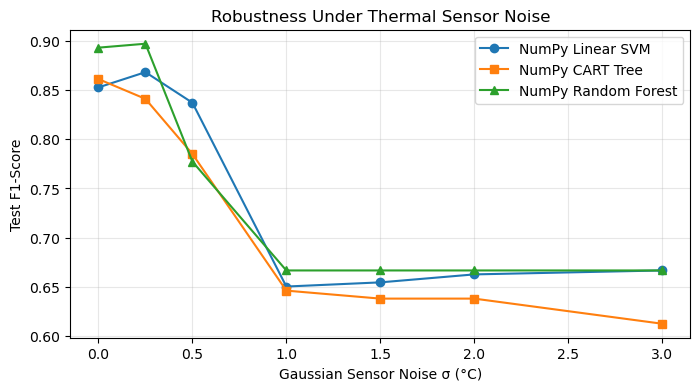

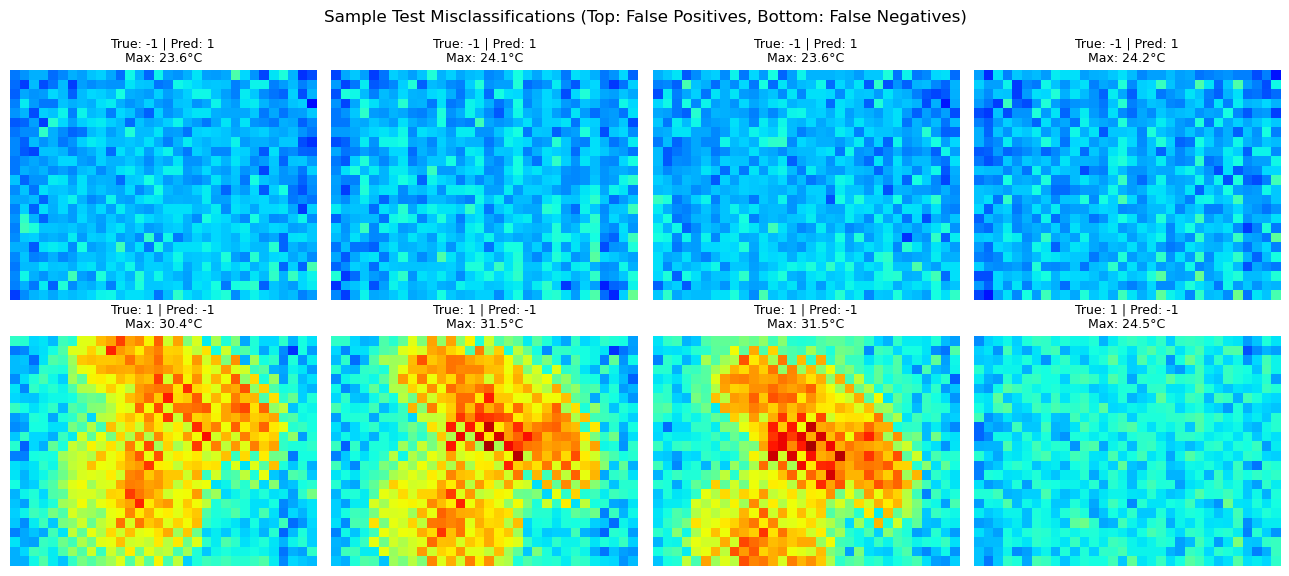

In [ ]:
# GAUSSIAN SENSOR NOISE STRESS TEST & ERROR VISUALISATION 

noise_levels = [0.0, 0.25, 0.5, 1.0, 1.5, 2.0, 3.0]
rng_noise = np.random.default_rng(42)

svm_noise_f1, dt_noise_f1, rf_noise_f1 = [], [], []

for sigma in noise_levels:
    # Added sensor noise in °C directly to test thermal frames, re-extract features, and scale
    noisy_X = np.vstack([
        extract_thermal_features(
            frames[i] + rng_noise.normal(0.0, sigma, size=frames[i].shape),
            bg_by_rec[rec_names[i]]
        )
        for i in test_idx
    ])
    noisy_X_scaled = scaler.transform(noisy_X)

    p_svm, _ = predict_linear_svm(noisy_X_scaled, best_svm["w"], best_svm["b"])
    p_dt     = predict_decision_tree(noisy_X_scaled, best_dt["tree"])
    p_rf     = predict_random_forest(noisy_X_scaled, best_rf_model)

    svm_noise_f1.append(f1_score(y_test, p_svm, pos_label=1, zero_division=0))
    dt_noise_f1.append(f1_score(y_test, p_dt, pos_label=1, zero_division=0))
    rf_noise_f1.append(f1_score(y_test, p_rf, pos_label=1, zero_division=0))

plt.figure(figsize=(8, 4))
plt.plot(noise_levels, svm_noise_f1, marker="o", label="NumPy Linear SVM")
plt.plot(noise_levels, dt_noise_f1,  marker="s", label="NumPy CART Tree")
plt.plot(noise_levels, rf_noise_f1,  marker="^", label="NumPy Random Forest")
plt.xlabel("Gaussian Sensor Noise σ (°C)")
plt.ylabel("Test F1-Score")
plt.title("Robustness Under Thermal Sensor Noise")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# Plotted up to 4 False Positives and 4 False Negatives from NumPy CART Tree
fp_pos = np.where((y_test == -1) & (dt_test_preds == 1))[0][:4]
fn_pos = np.where((y_test == 1) & (dt_test_preds == -1))[0][:4]
err_pos = np.concatenate([fp_pos, fn_pos])

if len(err_pos) > 0:
    fig, axes = plt.subplots(2, 4, figsize=(13, 6))
    axes = axes.flatten()
    for i, pos in enumerate(err_pos):
        orig_i = test_idx[pos]
        axes[i].imshow(frames[orig_i], cmap="jet", vmin=17, vmax=32, interpolation="nearest")
        axes[i].set_title(f"True: {y_test[pos]} | Pred: {dt_test_preds[pos]}\nMax: {frames[orig_i].max():.1f}°C", fontsize=9)
        axes[i].axis("off")
    for j in range(len(err_pos), len(axes)):
        axes[j].axis("off")
    plt.suptitle("Sample Test Misclassifications (Top: False Positives, Bottom: False Negatives)")
    plt.tight_layout()
    plt.show()

## 8b. Robustness (b): isolated hot-pixel glitches
This is the proposal's "single bad pixel" scenario. We add *k* spurious +6 °C pixels at random positions to **empty** test frames and measure the false-alarm rate.

**Finding (negative result).** **One** glitched pixel makes every model raise a false alarm on essentially **100 %** of empty frames. The reason is that our strongest features (max heat, max contrast, max gradient) are *maximum-based*, so one pixel dominates them. So accuracy on clean frames overstated how reliable the pipeline would be on a faulty sensor.


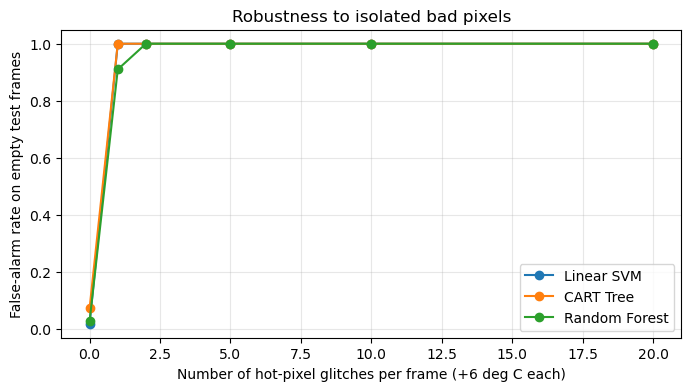

,Linear SVM,CART Tree,Random Forest
glitches,,,
0,0.018,0.072,0.027
1,1.000,1.000,0.910
2,1.000,1.000,1.000
5,1.000,1.000,1.000
10,1.000,1.000,1.000
20,1.000,1.000,1.000


In [62]:
# Isolated hot-pixel glitch test (the proposal's "single bad pixel" scenario) 
# Add k spurious +GLITCH_C deg C pixels at random positions to every test frame, re-extract features.
GLITCH_C = 6.0
glitch_counts = [0, 1, 2, 5, 10, 20]
rng_g = np.random.default_rng(7)
empty_pos = np.where(y_test == -1)[0]          # false-alarm rate is measured on truly empty frames
glitch_fpr = {"Linear SVM": [], "CART Tree": [], "Random Forest": []}

for k in glitch_counts:
    Xg = []
    for pos in empty_pos:
        i = test_idx[pos]
        f = frames[i].copy()
        if k > 0:
            px = rng_g.choice(f.size, size=k, replace=False)
            f.flat[px] += GLITCH_C
        Xg.append(extract_thermal_features(f, bg_by_rec[rec_names[i]]))
    Xg = scaler.transform(np.vstack(Xg))
    glitch_fpr["Linear SVM"].append(np.mean(predict_linear_svm(Xg, best_svm["w"], best_svm["b"])[0] == 1))
    glitch_fpr["CART Tree"].append(np.mean(predict_decision_tree(Xg, best_dt["tree"]) == 1))
    glitch_fpr["Random Forest"].append(np.mean(predict_random_forest(Xg, best_rf_model) == 1))

plt.figure(figsize=(8, 4))
for name, vals in glitch_fpr.items():
    plt.plot(glitch_counts, vals, marker="o", label=name)
plt.xlabel(f"Number of hot-pixel glitches per frame (+{GLITCH_C:.0f} deg C each)")
plt.ylabel("False-alarm rate on empty test frames"); plt.grid(True, alpha=0.3); plt.legend()
plt.title("Robustness to isolated bad pixels"); plt.show()
display(pd.DataFrame(glitch_fpr, index=glitch_counts).rename_axis("glitches").round(3))


## 8c. Fix: 3 × 3 median filter before feature extraction
**Idea.** A person covers several neighbouring pixels; a glitch covers one. A 3 × 3 median filter keeps the former and removes the latter. We apply it to every frame (and the background) before feature extraction and **re-fit the scaler and all three models on the training set only**, with the same tuned hyper-parameters.

**Result.** Clean performance changes only slightly (validation F1 is about 0.01–0.04 lower; test F1 ≈ 0.85 / 0.85 / 0.90 for SVM / tree / forest). The glitch failure largely disappears: even with **20 glitched pixels** the false-alarm rate stays around **0.05–0.13** instead of 1.0.

**Trade-off.** A tiny hand-warm spot (< 2–3 pixels) would also be smoothed away, which would matter for very small targets. 


Robust pipeline (median-filtered) - VALIDATION


,Acc,Prec,Recall,F1,FPR
Model,,,,,
Linear SVM,0.896,0.957,0.761,0.848,0.021
CART Tree,0.839,0.800,0.773,0.786,0.120
Random Forest,0.870,0.872,0.773,0.819,0.070


Robust pipeline (median-filtered) - TEST (reported once)


,Acc,Prec,Recall,F1,FPR
Model,,,,,
Linear SVM,0.865,0.966,0.757,0.848,0.027
CART Tree,0.856,0.891,0.811,0.849,0.099
Random Forest,0.905,0.959,0.847,0.900,0.036


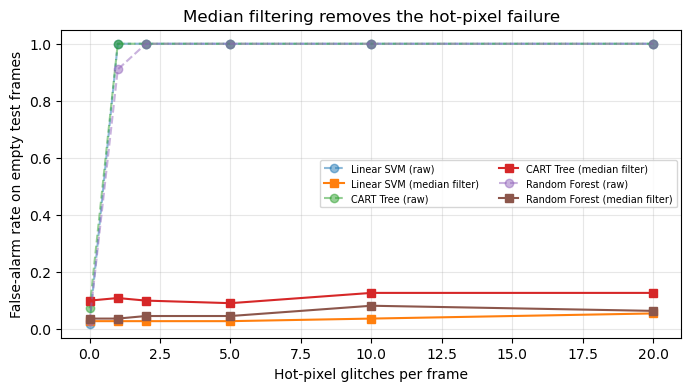

,Linear SVM,CART Tree,Random Forest
glitches,,,
0,0.027,0.099,0.036
1,0.027,0.108,0.036
2,0.027,0.099,0.045
5,0.027,0.090,0.045
10,0.036,0.126,0.081
20,0.054,0.126,0.063


In [63]:
# Mitigation: 3x3 median filter before feature extraction
# A real person covers several neighbouring pixels; a glitch is one pixel. A 3x3 median keeps
# the first and removes the second. Everything is re-fitted on TRAIN only (same hyper-parameters).
from scipy.ndimage import median_filter

def extract_features_robust(frame, bg):
    return extract_thermal_features(median_filter(frame, size=3, mode="nearest"),
                                    median_filter(bg,    size=3, mode="nearest"))

def build_feature_matrix_robust(indices):
    return np.vstack([extract_features_robust(frames[i], bg_by_rec[rec_names[i]]) for i in indices])

Xr_train, Xr_val, Xr_test = (build_feature_matrix_robust(ix) for ix in (train_idx, val_idx, test_idx))
scaler_r = StandardScaler().fit(Xr_train)
Ar, Br, Cr = scaler_r.transform(Xr_train), scaler_r.transform(Xr_val), scaler_r.transform(Xr_test)

w_r, b_r, _ = train_linear_svm(Ar, y_train, learning_rate=best_svm["lr"], lambda_reg=best_svm["lam"],
                               epochs=400, random_state=42)
tree_r = build_decision_tree(Ar, y_train, max_depth=best_dt["depth"], min_samples_split=10,
                             min_samples_leaf=best_dt["leaf"], min_impurity_decrease=1e-5)
forest_r = train_random_forest(Ar, y_train, n_trees=40, max_depth=max(best_dt["depth"], 6),
                               min_samples_split=10, min_samples_leaf=best_dt["leaf"],
                               max_features=8, random_state=42)

def robust_predict(X):
    return {"Linear SVM": predict_linear_svm(X, w_r, b_r)[0],
            "CART Tree": predict_decision_tree(X, tree_r),
            "Random Forest": predict_random_forest(X, forest_r)}

def summarize(y, preds):
    rows = []
    for n, p in preds.items():
        neg = (y == -1)
        rows.append([n, accuracy_score(y, p), precision_score(y, p, pos_label=1, zero_division=0),
                     recall_score(y, p, pos_label=1, zero_division=0),
                     f1_score(y, p, pos_label=1, zero_division=0), ((p == 1) & neg).sum() / neg.sum()])
    return pd.DataFrame(rows, columns=["Model", "Acc", "Prec", "Recall", "F1", "FPR"]).set_index("Model").round(3)

print("Robust pipeline (median-filtered) - VALIDATION"); display(summarize(y_val, robust_predict(Br)))
print("Robust pipeline (median-filtered) - TEST (reported once)"); display(summarize(y_test, robust_predict(Cr)))

# Re-ran the hot-pixel test on the robust pipeline
rng_g2 = np.random.default_rng(7)
robust_fpr = {"Linear SVM": [], "CART Tree": [], "Random Forest": []}
for k in glitch_counts:
    Xg = []
    for pos in empty_pos:
        i = test_idx[pos]; f = frames[i].copy()
        if k > 0:
            f.flat[rng_g2.choice(f.size, size=k, replace=False)] += GLITCH_C
        Xg.append(extract_features_robust(f, bg_by_rec[rec_names[i]]))
    pg = robust_predict(scaler_r.transform(np.vstack(Xg)))
    for n in robust_fpr: robust_fpr[n].append(float(np.mean(pg[n] == 1)))

plt.figure(figsize=(8, 4))
for n in robust_fpr:
    plt.plot(glitch_counts, glitch_fpr[n], "--", marker="o", alpha=0.5, label=f"{n} (raw)")
    plt.plot(glitch_counts, robust_fpr[n], "-", marker="s", label=f"{n} (median filter)")
plt.xlabel("Hot-pixel glitches per frame"); plt.ylabel("False-alarm rate on empty test frames")
plt.title("Median filtering removes the hot-pixel failure"); plt.grid(True, alpha=0.3); plt.legend(fontsize=7, ncol=2)
plt.show()
display(pd.DataFrame(robust_fpr, index=glitch_counts).rename_axis("glitches").round(3))


## 9. Real-time feasibility (end-to-end latency)
The sensor delivers **16 frames per second, i.e. 62.5 ms per frame**. We time the **whole path for one frame at a time** (feature extraction → scaling → prediction), which is what a live system would do.

**Finding.** Every model needs **about 1–1.3 ms per frame, roughly 2 % of the budget**. Feature extraction alone is ≈ 0.7 ms and dominates the cost of the SVM and tree; the forest adds a little more. So *speed does not decide the model choice*: all are far inside real time on a laptop CPU. (Timings depend on the machine and are only indicative; we did not test a microcontroller.)


In [64]:
# End-to-end latency: feature extraction + scaling + prediction, ONE frame at a time
def time_pipeline(predict_one, n=200):
    t0 = time.perf_counter()
    for pos in range(n):
        i = test_idx[pos]
        x = extract_thermal_features(frames[i], bg_by_rec[rec_names[i]])
        predict_one(scaler.transform(x.reshape(1, -1)))
    return (time.perf_counter() - t0) / n * 1000.0

lat = {
    "NumPy Linear SVM":    time_pipeline(lambda x: predict_linear_svm(x, best_svm["w"], best_svm["b"])),
    "NumPy CART Tree":     time_pipeline(lambda x: predict_decision_tree(x, best_dt["tree"])),
    "NumPy Random Forest": time_pipeline(lambda x: predict_random_forest(x, best_rf_model)),
}
t0 = time.perf_counter()
for pos in range(200):
    i = test_idx[pos]; extract_thermal_features(frames[i], bg_by_rec[rec_names[i]])
feat_ms = (time.perf_counter() - t0) / 200 * 1000.0

lat_df = pd.DataFrame({"end-to-end ms/frame": lat})
lat_df["share of 62.5 ms budget (%)"] = lat_df["end-to-end ms/frame"] / FRAME_BUDGET_MS * 100
display(lat_df.round(3))
print(f"Feature extraction alone: {feat_ms:.3f} ms/frame  (it dominates the cost of the cheap models)")
print(f"Real-time budget at {FPS} Hz = {FRAME_BUDGET_MS:.1f} ms per frame.")


,end-to-end ms/frame,share of 62.5 ms budget (%)
NumPy Linear SVM,0.770,1.232
NumPy CART Tree,0.696,1.113
NumPy Random Forest,0.938,1.502


Feature extraction alone: 0.611 ms/frame  (it dominates the cost of the cheap models)
Real-time budget at 16 Hz = 62.5 ms per frame.


## 10. Which features matter? Answering the research question directly
The proposal's idea is that **spatial gradients** enable a simple linear model. To test it, we retrained each model on feature subsets (hyper-parameters fixed, **validation F1 only**).

| Feature group | SVM | Tree | Forest |
|---|---|---|---|
| A. Gradient only (4) | ≈ 0.53 | ≈ 0.54 | ≈ 0.55 |
| B. Heat above background (8) | ≈ 0.81 | ≈ 0.80 | ≈ 0.81 |
| C. Contrast + gradient, no background (8) | ≈ 0.85 | ≈ 0.82 | ≈ 0.82 |
| D. Zone pooling (24) | ≈ 0.76 | ≈ 0.79 | ≈ 0.79 |
| E. All (40) | ≈ 0.86 | ≈ 0.82 | ≈ 0.82 |

**Conclusion.** Spatial gradients **alone are not enough** (F1 ≈ 0.53–0.55, barely better than flagging everything). Their value is *in combination* with heat/contrast features: group C (8 features, **no empty-room calibration needed**) comes close to using all 40. 


In [65]:
# Feature groups (index ranges inside the 40-column feature vector) 
FEATURE_GROUPS = {
    "A. Gradient only (4)":                  list(range(12, 16)),
    "B. Background-subtracted heat (8)":     list(range(0, 8)),
    "C. Contrast + gradient, no bg (8)":     list(range(8, 16)),
    "D. 3x4 zone pooling (24)":              list(range(16, 40)),
    "E. All features (40)":                  list(range(40)),
}


,SVM F1,Tree F1,Forest F1
Feature group,,,
A. Gradient only (4),0.526,0.565,0.562
B. Background-subtracted heat (8),0.812,0.800,0.814
"C. Contrast + gradient, no bg (8)",0.845,0.817,0.817
D. 3x4 zone pooling (24),0.758,0.786,0.790
E. All features (40),0.862,0.821,0.821


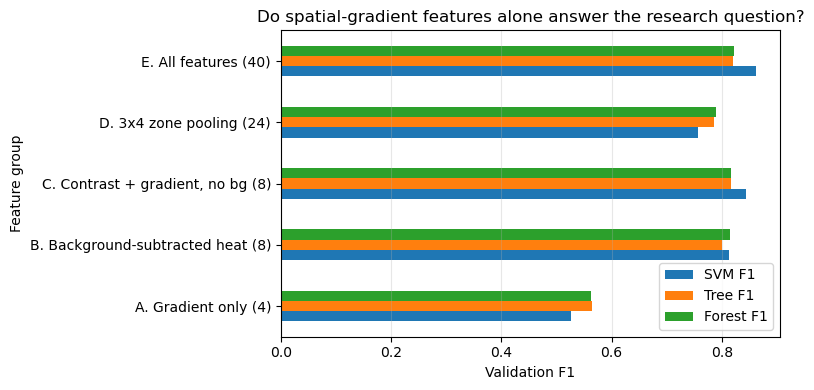

In [66]:
# Which features matter? (VALIDATION data only; hyper-parameters fixed from tuning)
def fit_and_score(cols):
    Xt, Xv = X_train_scaled[:, cols], X_val_scaled[:, cols]
    w_, b_, _ = train_linear_svm(Xt, y_train, learning_rate=best_svm["lr"],
                                 lambda_reg=best_svm["lam"], epochs=400, random_state=42)
    p_svm, _ = predict_linear_svm(Xv, w_, b_)
    tree_ = build_decision_tree(Xt, y_train, max_depth=best_dt["depth"], min_samples_split=10,
                                min_samples_leaf=best_dt["leaf"], min_impurity_decrease=1e-5)
    p_dt = predict_decision_tree(Xv, tree_)
    rf_ = train_random_forest(Xt, y_train, n_trees=40, max_depth=max(best_dt["depth"], 6),
                              min_samples_split=10, min_samples_leaf=best_dt["leaf"],
                              max_features=max(2, int(np.sqrt(len(cols)))), random_state=42)
    p_rf = predict_random_forest(Xv, rf_)
    return [f1_score(y_val, p, pos_label=1, zero_division=0) for p in (p_svm, p_dt, p_rf)]

abl_rows = []
for name, cols in FEATURE_GROUPS.items():
    abl_rows.append([name] + fit_and_score(cols))
abl = pd.DataFrame(abl_rows, columns=["Feature group", "SVM F1", "Tree F1", "Forest F1"]).set_index("Feature group")
display(abl.round(3))

ax = abl.plot(kind="barh", figsize=(8, 4))
ax.set_xlabel("Validation F1"); ax.set_title("Do spatial-gradient features alone answer the research question?")
ax.grid(True, axis="x", alpha=0.3); plt.tight_layout(); plt.show()


## 11. Lasso feature filtering (coordinate descent)
We fit a Lasso regression on the ±1 target:

$$\min_w\ \tfrac1{2n}\lVert y-Xw\rVert_2^2+\alpha\lVert w\rVert_1,$$

solved by cyclic **coordinate descent** with the soft-threshold update $w_j\leftarrow S(\rho_j,\alpha)/\tfrac1n\lVert X_j\rVert^2$. Larger α drives more coefficients exactly to zero. α is chosen on **validation F1**.

**Finding.** The best α keeps **34 of 40** features, and a very sparse model (7 features) still reaches F1 ≈ 0.80, versus ≈ 0.83 for the best α. The signal is spread over many correlated features, so Lasso gives a modest, interpretable reduction rather than a dramatic one. A linear SVM on the Lasso-selected features scores F1 ≈ 0.85 on validation (≈ 0.86 with all 40), so little is lost.


,alpha,n_features_kept,val_F1
0,0.0010,37,0.8221
1,0.0016,34,0.8293
2,0.0026,29,0.8272
3,0.0042,25,0.8125
4,0.0068,20,0.8125
5,0.0109,15,0.7975
6,0.0176,12,0.7949
7,0.0284,7,0.8025
8,0.0459,5,0.7792
9,0.0740,4,0.7467


Best alpha on validation = 0.0016  ->  34 of 40 features kept


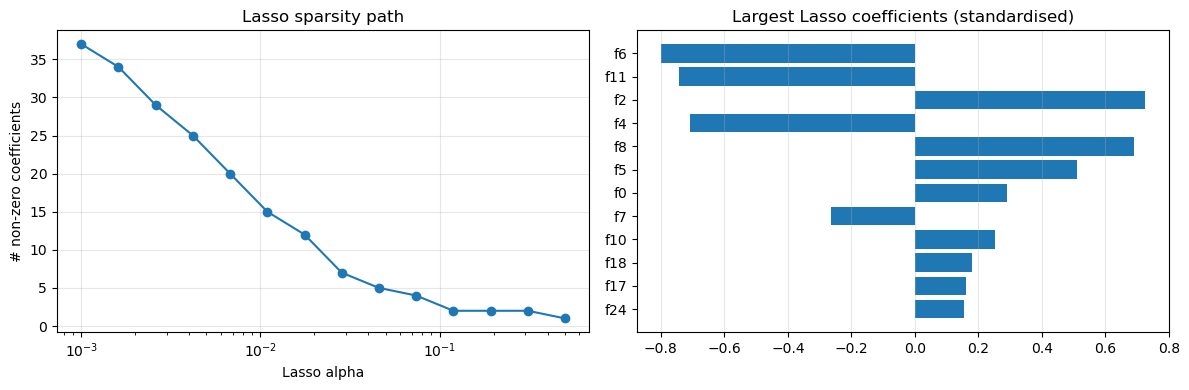

Linear SVM on 34 Lasso-selected features: val F1 = 0.8519  (all 40 features: 0.8625)


In [67]:
# Lasso (coordinate descent, pure NumPy) used as a feature filter 
def soft_threshold(rho, alpha):
    return np.sign(rho) * np.maximum(np.abs(rho) - alpha, 0.0)

def lasso_coordinate_descent(X, y, alpha, n_iter=300, tol=1e-7):
    """Minimise (1/2n)||y - Xw||^2 + alpha*||w||_1 on centred y (X already standardised)."""
    n, p = X.shape
    y_mean = y.mean()
    r = (y - y_mean).astype(np.float64)       # residual
    w = np.zeros(p)
    col_sq = (X ** 2).sum(axis=0) / n
    for _ in range(n_iter):
        w_old = w.copy()
        for j in range(p):
            r += X[:, j] * w[j]                # remove feature j from the fit
            rho = X[:, j] @ r / n
            w[j] = soft_threshold(rho, alpha) / col_sq[j]
            r -= X[:, j] * w[j]                # add it back
        if np.max(np.abs(w - w_old)) < tol:
            break
    return w, y_mean

alphas = np.logspace(-3, -0.3, 14)
rows, coefs = [], []
for a in alphas:
    w_l, y_mu = lasso_coordinate_descent(X_train_scaled, y_train.astype(float), a)
    pred = np.where(X_val_scaled @ w_l + y_mu >= 0, 1, -1)
    rows.append((a, int(np.sum(w_l != 0)), f1_score(y_val, pred, pos_label=1, zero_division=0)))
    coefs.append(w_l)
lasso_df = pd.DataFrame(rows, columns=["alpha", "n_features_kept", "val_F1"])
display(lasso_df.round(4))

best_a = lasso_df.loc[lasso_df["val_F1"].idxmax(), "alpha"]
w_best, _ = lasso_coordinate_descent(X_train_scaled, y_train.astype(float), best_a)
kept = np.where(w_best != 0)[0]
print(f"Best alpha on validation = {best_a:.4f}  ->  {len(kept)} of 40 features kept")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].semilogx(lasso_df["alpha"], lasso_df["n_features_kept"], "o-")
ax[0].set_xlabel("Lasso alpha"); ax[0].set_ylabel("# non-zero coefficients"); ax[0].grid(True, alpha=0.3)
ax[0].set_title("Lasso sparsity path")
order = np.argsort(-np.abs(w_best))[:12]
ax[1].barh([f"f{j}" for j in order][::-1], w_best[order][::-1])
ax[1].set_title("Largest Lasso coefficients (standardised)"); ax[1].grid(True, axis="x", alpha=0.3)
plt.tight_layout(); plt.show()

# Does the Lasso-filtered feature set keep the SVM accurate?  (validation only)
w_s, b_s, _ = train_linear_svm(X_train_scaled[:, kept], y_train, learning_rate=best_svm["lr"],
                               lambda_reg=best_svm["lam"], epochs=400, random_state=42)
p_s, _ = predict_linear_svm(X_val_scaled[:, kept], w_s, b_s)
print(f"Linear SVM on {len(kept)} Lasso-selected features: val F1 = "
      f"{f1_score(y_val, p_s, pos_label=1, zero_division=0):.4f}  "
      f"(all 40 features: {best_svm['f1']:.4f})")


## 12. Uncertainty and generalisation
### 12.1 Bootstrap confidence intervals on the test set
We resample the 222 test predictions with replacement 2,000 times (no refitting) to get 95 % intervals.

| Model | F1 (95 % CI) | False-positive rate (95 % CI) |
|---|---|---|
| Linear SVM | 0.85 [0.80, 0.90] | 0.02 [0.00, 0.05] |
| CART | 0.86 [0.81, 0.91] | 0.07 [0.03, 0.12] |
| Random Forest | 0.89 [0.84, 0.93] | 0.03 [0.00, 0.06] |

**Reading.** The F1 intervals overlap almost completely. The Random Forest's advantage is suggestive but **not statistically solid** with 222 frames. The clearest difference is the *single tree's higher false-positive rate*.


In [68]:
# Uncertainty on the final test result: bootstrap 95% CI (no refitting)
rng_bs = np.random.default_rng(0)
final_preds = {"Linear SVM": svm_test_preds, "CART Tree": dt_test_preds, "Random Forest": rf_test_preds}
boot_idx = [rng_bs.integers(0, len(y_test), len(y_test)) for _ in range(2000)]

def ci(metric, p):
    vals = [metric(y_test[i], p[i]) for i in boot_idx]
    return np.percentile(vals, [2.5, 97.5])

def fpr_metric(y, p):
    neg = (y == -1)
    return ((p == 1) & neg).sum() / max(1, neg.sum())

ci_rows = []
for name, p in final_preds.items():
    f_lo, f_hi = ci(lambda y, q: f1_score(y, q, pos_label=1, zero_division=0), p)
    r_lo, r_hi = ci(lambda y, q: recall_score(y, q, pos_label=1, zero_division=0), p)
    q_lo, q_hi = ci(fpr_metric, p)
    ci_rows.append([name, f"{f1_score(y_test, p, pos_label=1):.3f} [{f_lo:.3f}, {f_hi:.3f}]",
                    f"{recall_score(y_test, p, pos_label=1):.3f} [{r_lo:.3f}, {r_hi:.3f}]",
                    f"{fpr_metric(y_test, p):.3f} [{q_lo:.3f}, {q_hi:.3f}]"])
display(pd.DataFrame(ci_rows, columns=["Model", "F1 (95% CI)", "Recall (95% CI)", "False-positive rate (95% CI)"]).set_index("Model"))
print("With only 222 test frames the intervals overlap heavily: small gaps between models are not reliable.")


,F1 (95% CI),Recall (95% CI),False-positive rate (95% CI)
Model,,,
Linear SVM,"0.853 [0.796, 0.902]","0.757 [0.672, 0.833]","0.018 [0.000, 0.047]"
CART Tree,"0.861 [0.806, 0.911]","0.811 [0.733, 0.883]","0.072 [0.027, 0.124]"
Random Forest,"0.893 [0.844, 0.934]","0.829 [0.757, 0.894]","0.027 [0.000, 0.061]"


With only 222 test frames the intervals overlap heavily: small gaps between models are not reliable.


### 12.2 Leave-one-recording-out (LORO) generalisation
Each recording is held out in turn (training on the other recordings, scaler re-fitted per fold, tuned hyper-parameters reused). This is a harder test than our random-block split because the model sees a different session.

**Finding.** Averaged over the five held-out recordings: forest accuracy ≈ 0.86 / recall ≈ 0.79 / FPR ≈ 0.12; SVM ≈ 0.86 / 0.76 / 0.09; tree ≈ 0.81 / 0.73 / 0.16. Performance varies a lot by session: `Lecture` is almost perfect, but on `Lunch_Meeting_3` recall drops to **≈ 0.52–0.55**, and on `High_Activity` false alarms reach **≈ 0.31–0.33**. So the single test-split numbers in Section 7 are probably **optimistic** for a new room or session.

**Caveat.** The per-recording background still comes from that recording's own training-split empty frames, i.e. a short per-room calibration. Without such calibration (feature group C in Section 10) the pipeline is less dependent on it.


In [69]:
# Harder generalisation check: leave-one-recording-out (LORO) 
# Train on all other recordings, test on the held-out one. Hyper-parameters are the ones chosen
# on the validation set earlier (no new tuning here). Scaler is re-fitted on each training fold.
X_pool = np.vstack([X_train, X_val, X_test])
y_pool = np.concatenate([y_train, y_val, y_test])
r_pool = np.concatenate([rec_names[train_idx], rec_names[val_idx], rec_names[test_idx]])

loro_rows = []
for held in ["High_Activity", "Lecture", "Lunch_Meeting_1", "Lunch_Meeting_2", "Lunch_Meeting_3"]:
    te, tr = (r_pool == held), (r_pool != held)
    sc = StandardScaler().fit(X_pool[tr])
    Xtr, Xte = sc.transform(X_pool[tr]), sc.transform(X_pool[te])
    ytr, yte = y_pool[tr], y_pool[te]

    w_, b_, _ = train_linear_svm(Xtr, ytr, learning_rate=best_svm["lr"], lambda_reg=best_svm["lam"],
                                 epochs=300, random_state=42)
    preds = {"SVM": predict_linear_svm(Xte, w_, b_)[0]}
    t_ = build_decision_tree(Xtr, ytr, max_depth=best_dt["depth"], min_samples_split=10,
                             min_samples_leaf=best_dt["leaf"], min_impurity_decrease=1e-5)
    preds["Tree"] = predict_decision_tree(Xte, t_)
    f_ = train_random_forest(Xtr, ytr, n_trees=40, max_depth=max(best_dt["depth"], 6),
                             min_samples_split=10, min_samples_leaf=best_dt["leaf"],
                             max_features=8, random_state=42)
    preds["Forest"] = predict_random_forest(Xte, f_)

    for m, p in preds.items():
        neg = (yte == -1)
        loro_rows.append([held, m, int((yte == 1).sum()), int(neg.sum()),
                          accuracy_score(yte, p),
                          recall_score(yte, p, pos_label=1, zero_division=0),
                          ((p == 1) & neg).sum() / max(1, neg.sum())])

loro = pd.DataFrame(loro_rows, columns=["held-out recording", "model", "n(+1)", "n(-1)", "accuracy", "recall", "false-alarm rate"])
display(loro.round(3))
summary_loro = loro.groupby("model")[["accuracy", "recall", "false-alarm rate"]].mean().round(3)
print("Mean over the 5 held-out recordings:"); display(summary_loro)


,held-out recording,model,n(+1),n(-1),accuracy,recall,false-alarm rate
0,High_Activity,SVM,255,45,0.850,0.878,0.311
1,High_Activity,Tree,255,45,0.810,0.835,0.333
2,High_Activity,Forest,255,45,0.913,0.953,0.311
3,Lecture,SVM,10,150,1.000,1.000,0.000
4,Lecture,Tree,10,150,0.888,0.800,0.107
5,Lecture,Forest,10,150,0.981,1.000,0.020
6,Lunch_Meeting_1,SVM,65,394,0.954,0.754,0.013
7,Lunch_Meeting_1,Tree,65,394,0.869,0.785,0.117
8,Lunch_Meeting_1,Forest,65,394,0.946,0.785,0.028
9,Lunch_Meeting_2,SVM,40,54,0.787,0.650,0.111


Mean over the 5 held-out recordings:


,accuracy,recall,false-alarm rate
model,,,
Forest,0.862,0.790,0.117
SVM,0.860,0.760,0.094
Tree,0.809,0.733,0.162


## 14. Conclusions and limitations
**Answer to the research question.**
1. **Gradients alone cannot detect the events** (F1 ≈ 0.53–0.55). They help only when combined with heat/contrast features.
2. A **Linear SVM baseline is strong**: ≈ 0.87 accuracy, ≈ 0.98 precision, very few false alarms (≈ 0.02), but it misses about a quarter of events.
3. **Tree models add recall, not a clear overall jump.** A single tree catches more events but raises ~4× more false alarms. The Random Forest achieves the best F1 (≈ 0.89) with a low false-alarm rate, but its confidence interval overlaps the others.
4. **Real-time is not a constraint**: ≈ 1 ms per frame end to end vs a 62.5 ms budget.

**What we learned about robustness.** Models are fragile to heavy Gaussian noise (σ ≥ 1 °C) and were *completely* fooled by single hot pixels until we added a median filter.

**Limitations (stated plainly).**
- One sensor, one room layout, 6 recordings; LORO shows weaker results on some sessions.
- Labels mark *people crossing*, not equipment faults; "thermal event" is our operational definition.
- Classes were balanced by sub-sampling; the real-world event rate is much lower, so real false-alarm burden would differ.
- The forest was tuned less than the other models; test set is small (222 frames).
- 32 of the 40 features are computed relative to an empty-room background, which needs a short calibration per room.

**Possible next steps.** Temporal smoothing across consecutive frames, rerunning the noise test on the median-filtered pipeline, and testing on a second sensor.
